# Modular realization: preparation, transfer, and activation

This notebook follows information from an initially occupied mode into a specified memory. An overlap amplitude measures how much of the evolved packet remains aligned with the initial source mode. Its squared magnitude is the residual source probability. The fixed orthogonal complement is memory, and the hazard measures the rate of transfer relative to what remains available at the source. It then shows how a change in preparation changes the transfer law.

All calculations begin with explicit formulas and the routines in `code/`. The notebook reproduces the modular-construction checks and the manuscript's preparation/receiver figure without reference arrays. Allow under one minute to run it.

## Start with the packet and its evolution

In the paper's vacuum wedge construction, modular time $s$ determines rapidity $u=2\pi s$. The one-particle evolution acts by dilation,

$$
(U_u\psi)(p)=\psi(e^{-u}p),\qquad
\psi\in L^2(\mathbb R_+,dp/p).
$$

The measure $dp/p$ is part of this definition and is used throughout the overlap calculation. The connection to vacuum modular evolution is established analytically in the manuscript; here we check the resulting representation by integration.

For positive shape and scale parameters $h$ and $\ell$, prepare the normalized packet

$$
\psi_{h,\ell}(p)=\frac{(2\ell)^h p^h e^{-\ell p}}{\sqrt{\Gamma(2h)}},
\qquad \langle p\rangle=\frac{h}{\ell}.
$$

The gamma integral gives the overlap $G(u)=\operatorname{sech}^{2h}(u/2)$. Its squared magnitude is the probability remaining in the original mode:

$$
p_0(s)=\operatorname{sech}^{4h}(\pi s),\qquad r(s)=1-p_0(s).
$$

The partition stays fixed: the original mode is the source, and its orthogonal complement is the ideal memory. Coherent species labels carry an arbitrary superposition of diary states. Every label must have the same spatial evolution and relative phase, so the transfer preserves its entanglement with the reference. Equal population transfer alone would not establish this. Orthogonal vacuum flags give an erasure channel. For a Bell input of dimension $d$, the normalized reference information is $I(Q:M)/(2\log d)=r$, and the coherent information is $(2r-1)\log d$.

The first cell checks the overlaps by quadrature, the information formulas with finite density matrices, and the mean momentum by integration. Entropies use natural logarithms.

In [1]:
from pathlib import Path
import os, datetime
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
sys.path.insert(0, str(Path('code').resolve()))
OUTPUT = Path('outputs/runs') / os.environ.get('ODER_RUN_NAME', datetime.datetime.now().strftime('%Y%m%d_%H%M%S')) / 'modular'
OUTPUT.mkdir(parents=True, exist_ok=True)
pd.set_option('display.precision', 10)

from modular_checks import dilation_survival, diamond_checks, finite_detector
from translated_packet_checks import translated_checks
from scipy.integrate import quad
from scipy.special import gamma
endpoint=dilation_survival()
display(pd.DataFrame(endpoint['samples']).head(10))
display(pd.DataFrame(endpoint['errors'].items(),columns=['check','maximum_error']))
energies=[]
for h,ell in [(.5,.7),(1.,1.3),(1.5,.7)]:
    energy=quad(lambda p:(2*ell)**(2*h)/gamma(2*h)*p**(2*h)*np.exp(-2*ell*p),0,np.inf)[0]
    assert abs(energy-h/ell)<1e-10
    energies.append([h,ell,energy,h/ell])
display(pd.DataFrame(energies,columns=['h','ell','mean_momentum_integral','h/ell']))

,h,ell,u,norm_integral,overlap_integral,overlap_exact,quadrature_reported_error,survival,retrieval,hazard,r_from_entropy,coherent_information_nats
0,0.5,0.7,0.0,1.0,1.0000000000,1.0000000000,7.7859740214e-13,1.0000000000,0.0000000000,0.0000000000,1.6017132519e-16,-0.6931471806
1,0.5,0.7,0.5,1.0,0.9695436291,0.9695436291,1.4715849820e-12,0.9400148488,0.0599851512,0.2449186624,5.9985151194e-02,-0.6099901037
2,0.5,0.7,1.0,1.0,0.8868188840,0.8868188840,1.2910363427e-12,0.7864477330,0.2135522670,0.4621171573,2.1355226703e-01,-0.3971008770
3,0.5,0.7,2.0,1.0,0.6480542737,0.6480542737,1.8784869812e-12,0.4199743416,0.5800256584,0.7615941560,5.8002565839e-01,0.1109391190
4,0.5,0.7,4.0,1.0,0.2658022288,0.2658022288,1.9115408911e-12,0.0706508249,0.9293491751,0.9640275801,9.2934917515e-01,0.5952043405
5,0.5,1.3,0.0,1.0,1.0000000000,1.0000000000,3.1461305201e-13,1.0000000000,0.0000000000,0.0000000000,1.6017132519e-16,-0.6931471806
6,0.5,1.3,0.5,1.0,0.9695436291,0.9695436291,7.3798708668e-13,0.9400148488,0.0599851512,0.2449186624,5.9985151194e-02,-0.6099901037
7,0.5,1.3,1.0,1.0,0.8868188840,0.8868188840,8.3243917599e-13,0.7864477330,0.2135522670,0.4621171573,2.1355226703e-01,-0.3971008770
8,0.5,1.3,2.0,1.0,0.6480542737,0.6480542737,1.6581815526e-12,0.4199743416,0.5800256584,0.7615941560,5.8002565839e-01,0.1109391190
9,0.5,1.3,4.0,1.0,0.2658022288,0.2658022288,1.5597331082e-12,0.0706508249,0.9293491751,0.9640275801,9.2934917515e-01,0.5952043405


,check,maximum_error
0,norm,4.4408920985e-16
1,overlap,2.2204460493e-16
2,hazard,4.7313042373e-11
3,reference_information,2.2204460493e-16
4,coherent_information,2.2204460493e-16
5,isometry,1.5700924587e-16
6,minimum_choi_eigenvalue,0.0000000000e+00


,h,ell,mean_momentum_integral,h/ell
0,0.5,0.7,0.7142857143,0.7142857143
1,1.0,1.3,0.7692307692,0.7692307692
2,1.5,0.7,2.1428571429,2.1428571429


## From source decay to activation

The hazard measures the loss rate relative to the population still in the source. Differentiating the logarithm of the residual probability gives

$$
k_s=-\partial_s\log p_0=4h\pi\tanh(\pi s),\qquad
A(s)=\frac{k_s}{4h\pi}=\tanh(\pi s).
$$

The hazard approaches $4h\pi$, which sets the kinetic scale. Activation expresses the rate as a fraction of that scale.

The coherent-state coordinate $z$ is the complex disk parameter labeling the normalized packet expansion. Along this evolution, $z_s=-i\tanh(\pi s)$, so the fixed rotation $w=iz$ gives $w=A$. The binomial series normalizes the expansion, and the generator acts on the disk through

$$
T_s(w)=\frac{w+\tanh(\pi s)}{1+w\tanh(\pi s)}.
$$

Does this activation belong to the analytic class used by the sharp bound? The following identity establishes membership throughout the complex strip; the grid illustrates it:

$$
|\tanh\pi(x+iy)|^2=
\frac{\sinh^2(\pi x)+\sin^2(\pi y)}
{\cosh^2(\pi x)-\sin^2(\pi y)}<1,
\qquad |y|<\tfrac14.
$$

The denominator exceeds the numerator by $\cos(2\pi y)>0$, and the poles lie outside this strip. This establishes global strip-to-disk membership. The complex grid below illustrates that identity. On the real axis, the derivative attains the bound $A'=\pi(1-A^2)$.

### Specify the clock

Modular time is dimensionless. With $s=c\tau$, where $\tau$ is proper time and $c$ specifies the clock conversion,

$$
\gamma=4h\pi c,\qquad \tau_{\rm char}=\frac{1}{\pi c},\qquad
\gamma\tau_{\rm char}=4h.
$$

The implemented chain uses $c=\Omega/\pi$. For an active boost, the packet energy ratio is $q_E=e^{2\pi s}$ and

$$
1-r=\left[\frac{4q_E}{(1+q_E)^2}\right]^{2h}.
$$

Here $q_E$ describes the boosted preparation's energy. A receiver's energy budget is a separate physical quantity.

The next cell compares a finite-difference hazard with the exact activation and checks the energy relation.

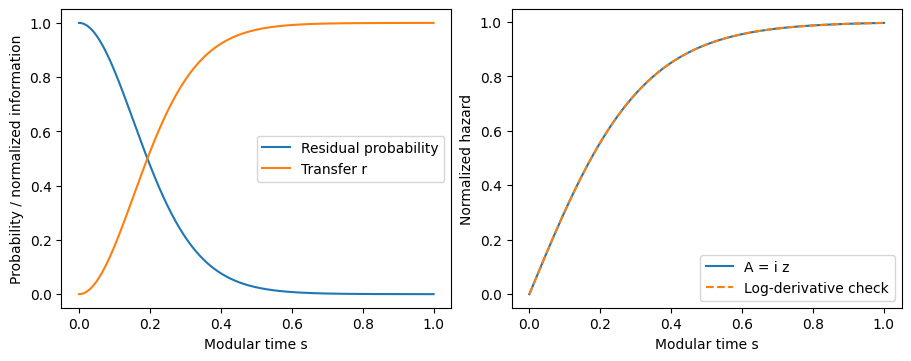

Illustrative complex-grid maximum: 0.9999999999181631
Conformal clock: t=T tanh(pi s); the same activation is t/T, not tanh in t.


In [2]:
s=np.linspace(0,1,501);h=1.
residual=np.cosh(np.pi*s)**(-4*h); transfer=1-residual
activation=np.tanh(np.pi*s); z=-1j*activation
step=1e-5
logp=lambda x:-4*h*np.log(np.cosh(np.pi*x))
numerical_hazard=-(logp(s+step)-logp(s-step))/(2*step)
assert np.max(abs(numerical_hazard/(4*h*np.pi)-activation))<1e-9
assert np.max(abs(1j*z-activation))<1e-14
qE=np.exp(2*np.pi*s)
assert np.max(abs(residual-(4*qE/(1+qE)**2)**(2*h)))<1e-14
fig,axs=plt.subplots(1,2,figsize=(9,3.5),layout='constrained')
axs[0].plot(s,residual,label='Residual probability');axs[0].plot(s,transfer,label='Transfer r')
axs[0].set(xlabel='Modular time s',ylabel='Probability / normalized information');axs[0].legend()
axs[1].plot(s,activation,label='A = i z');axs[1].plot(s,numerical_hazard/(4*h*np.pi),'--',label='Log-derivative check')
axs[1].set(xlabel='Modular time s',ylabel='Normalized hazard');axs[1].legend()
fig.savefig(OUTPUT/'modular_transfer.png',dpi=180);plt.show()
geometry=diamond_checks()
print('Illustrative complex-grid maximum:',geometry['sampled_max_abs_interior'])
print('Conformal clock: t=T tanh(pi s); the same activation is t/T, not tanh in t.')

## How a translated preparation changes the result

Multiplying the packet by $e^{-ilp}$ introduces a translation $l$. The source projector now refers to this translated initial packet. Define

$$
b=\frac{\ell^2}{\ell^2+l^2},\qquad
p_b(s)=\left[\frac{b}{b+\sinh^2(\pi s)}\right]^{2h},\qquad
A_b(s)=\frac{\sinh(\pi s)\cosh(\pi s)}{b+\sinh^2(\pi s)}.
$$

These expressions make the dependence on preparation explicit. Writing $y=\sinh^2(\pi s)$ gives

$$
\frac{A'_b}{\pi}=\frac{b+(2b-1)y}{(b+y)^2}.
$$

For $b\geq1/2$, the activation is monotone. For $b<1/2$, it reaches a maximum at $y=b/(1-2b)$, with

$$
A_{\max}=\frac{1}{2\sqrt{b(1-b)}}>1.
$$

Every translated case with $b<1$ leaves the original strip class, including the monotone cases: its initial slope is $A'_b(0)=\pi/b>\pi$. This conclusion follows from the formulas for the entire family.

The quadrature checks use $h=0.5,1,1.5$, $\ell=1$, translations $l=0,0.5,1,2$, and times $s=0.1,0.5,1$. The manuscript figure uses $b=1,0.75,0.25$.

In [3]:
translated=translated_checks()
display(pd.DataFrame(translated['samples']))
print('Maximum translated overlap-probability discrepancy:',translated['maximum_error'])
rows=[]
for b in [1.,.75,.25]:
    peak_x=np.arcsinh(np.sqrt(b/(1-2*b))) if b<.5 else np.nan
    peak=1/(2*np.sqrt(b*(1-b))) if b<.5 else 1.
    rows.append([b,np.pi/b,peak_x,peak])
display(pd.DataFrame(rows,columns=['b','slope at s=0','peak pi*s (finite only if b<1/2)','maximum or limit']))

,h,ell,l,s,b,quadrature_survival,analytic_survival,error
0,0.5,1.0,0.0,0.1,1.0,0.9074525080,0.9074525080,6.1062266354e-15
1,0.5,1.0,0.0,0.5,1.0,0.1588315932,0.1588315932,2.7755575616e-17
2,0.5,1.0,0.0,1.0,1.0,0.0074419501,0.0074419501,1.7347234760e-18
3,0.5,1.0,0.5,0.1,0.8,0.8869316823,0.8869316823,1.1102230246e-16
4,0.5,1.0,0.5,0.5,0.8,0.1312340987,0.1312340987,2.4980018054e-16
5,0.5,1.0,0.5,1.0,0.8,0.0059624345,0.0059624345,1.7347234760e-18
6,0.5,1.0,1.0,0.1,0.5,0.8305840383,0.8305840383,0.0000000000e+00
7,0.5,1.0,1.0,0.5,0.5,0.0862667383,0.0862667383,0.0000000000e+00
8,0.5,1.0,1.0,1.0,0.5,0.0037348724,0.0037348724,8.6736173799e-19
9,0.5,1.0,2.0,0.1,0.2,0.6622822595,0.6622822595,1.1102230246e-16


Maximum translated overlap-probability discrepancy: 1.8818280267396403e-13


,b,slope at s=0,peak pi*s (finite only if b<1/2),maximum or limit
0,1.00,3.1415926536,NaN,1.0000000000
1,0.75,4.1887902048,NaN,1.0000000000
2,0.25,12.5663706144,0.6584789485,1.1547005384


## Reproduce the manuscript figure

The two panels bring the preparation and finite-receiver results together. Panel (b) evaluates the analytic receiver certificate. `Finite_Receiver.ipynb` follows this with direct evolution of both receiver designs.

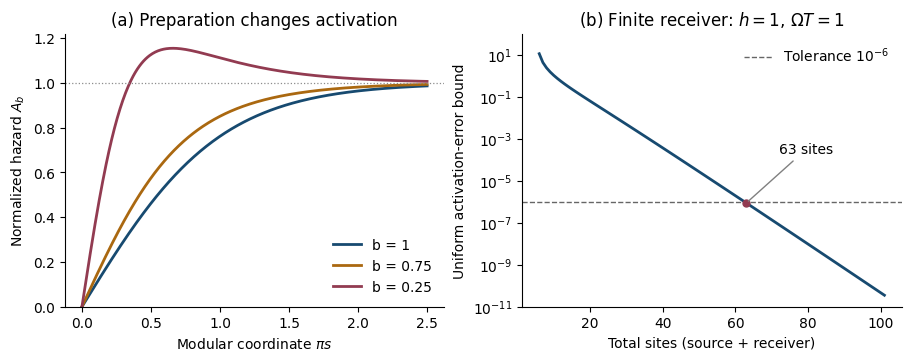

In [4]:
from figures import modular_bridge
fig=modular_bridge(OUTPUT)
plt.show()

## Compare with a resonant detector

The closed exchange example provides a useful comparison between excitation transfer and reference information. The weights $(0.8,0.2)$ specify the state defining the modular Hamiltonian. They are not the Bell reference marginal, which is $I/2$. The exchange coupling is $g=0.37$. The excitation probability is $p=\sin^2(g\tau)$, while the normalized reference information is

$$
\frac{\log2+H_2(p/2)-H_2((1-p)/2)}{2\log2},
$$

where $H_2$ is binary entropy in natural-log units. This detector therefore has a different probability-to-information relation from the flagged modal channel. The cell below evaluates both quantities so their distinction can be read directly from the output.

In [5]:
resonant=finite_detector()
display(pd.DataFrame(resonant['samples']))
display(pd.DataFrame(resonant['errors'].items(),columns=['independent check','error']))
print('At transfer probability 0.1:',resonant['nonlinear_example'])

,g_tau,tau,conditional_excitation_transfer,normalized_reference_information
0,0.0000000000,0.0000000000,0.0000000000e+00,1.6017132519e-16
1,0.7853981634,2.1226977389,5.0000000000e-01,5.0000000000e-01
2,1.5707963268,4.2453954778,1.0000000000e+00,1.0000000000e+00
3,2.3561944902,6.3680932167,5.0000000000e-01,5.0000000000e-01
4,3.1415926536,8.4907909556,1.4997597827e-32,1.2813706015e-15
5,6.2831853072,16.9815819113,5.9990391306e-32,2.2423985527e-15


,independent check,error
0,density_error,4.4368571665e-15
1,information_error,2.2423985527e-15
2,probability_error,6.4392935428e-15


At transfer probability 0.1: {'transfer_probability': 0.1, 'reference_information': np.float64(0.14681125156407393)}


## Compare preparations at the same generator variance

At a common modular parameter, a translated packet transfers more information but also has greater generator variance. To compare at fixed variance, use each translated packet's matched source projector and the common dilation generator $K$. Its physical generator is $H_b=c_bK$, with

$$\operatorname{Var}_{\psi_b}(K)=2h\pi^2/b,\qquad c_b=\sigma\sqrt b/(\pi\sqrt{2h}).$$

Writing $x=\sigma t/\sqrt{2h}$ gives

$$r_b(t)=1-\left[1+\sinh^2(\sqrt b\,x)/b\right]^{-2h}\le r_1(t).$$

The analytic ordering follows because $\sinh y/y$ increases strictly for positive $y$. Its derivative has numerator $y\cosh y-\sinh y$, which starts at zero and has positive derivative $y\sinh y$. Equality holds at $t=0$ or $b=1$; otherwise the centered preparation transfers strictly more. The grid illustrates that result. Independent packet and generator quadratures check the formulas.

The comparison changes the physical generator scale and source projector. It does not hold every physical generator or late-time hazard fixed.

,h,b,sigma,time,variance_K_quadrature,variance_K_formula,c_b,physical_variance,transfer,centered_transfer,overlap_probability_residual
0,0.5,1.00,1.0,0.0,9.8696044011,9.8696044011,0.3183098862,1.0,0.0000000000,0.0000000000,4.4408920985e-16
1,0.5,1.00,1.0,0.2,9.8696044011,9.8696044011,0.3183098862,1.0,0.0389570170,0.0389570170,2.5673907444e-16
2,0.5,1.00,1.0,1.0,9.8696044011,9.8696044011,0.3183098862,1.0,0.5800256584,0.5800256584,1.1102230246e-16
3,0.5,1.00,1.0,2.0,9.8696044011,9.8696044011,0.3183098862,1.0,0.9293491751,0.9293491751,0.0000000000e+00
4,0.5,0.75,1.0,0.0,13.1594725348,13.1594725348,0.2756644477,1.0,0.0000000000,0.0000000000,4.4408920985e-16
5,0.5,0.75,1.0,0.2,13.1594725348,13.1594725348,0.2756644477,1.0,0.0388327001,0.0389570170,2.1510571102e-16
6,0.5,0.75,1.0,1.0,13.1594725348,13.1594725348,0.2756644477,1.0,0.5607069905,0.5800256584,2.2204460493e-16
7,0.5,0.75,1.0,2.0,13.1594725348,13.1594725348,0.2756644477,1.0,0.9090331496,0.9293491751,1.1102230246e-16
8,0.5,0.25,1.0,0.0,39.4784176044,39.4784176044,0.1591549431,1.0,0.0000000000,0.0000000000,4.4408920985e-16
9,0.5,0.25,1.0,0.2,39.4784176044,39.4784176044,0.1591549431,1.0,0.0385849613,0.0389570170,1.1796119637e-16


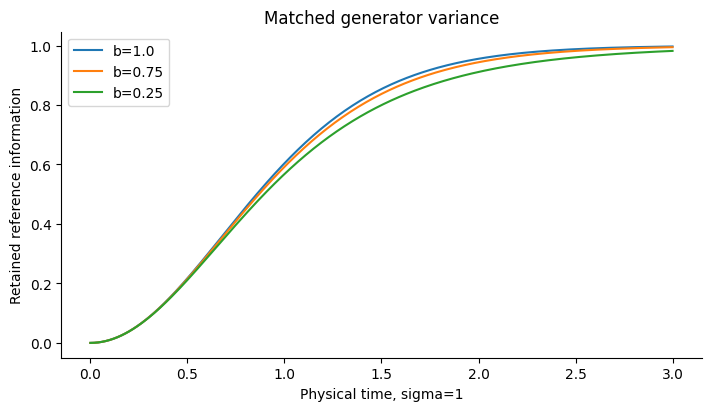

In [6]:
from preparation_variance import checks as variance_checks, transfer as variance_transfer
variance=pd.DataFrame(variance_checks())
display(variance)
variance.to_csv(OUTPUT/'fixed_variance.csv',index=False)
fig,ax=plt.subplots(figsize=(7,4),layout='constrained')
t=np.linspace(0,3,301)
for b in [1.,.75,.25]:ax.plot(t,variance_transfer(t,1.,b),label=f'b={b}')
ax.set(xlabel='Physical time, sigma=1',ylabel='Retained reference information',title='Matched generator variance')
ax.legend();fig.savefig(OUTPUT/'fixed_variance.png',dpi=170,metadata={'Software':None});plt.show()

## Reading the results

For the specified packet and fixed source–memory partition, overlap integration, density-matrix entropies, and the normalized hazard give consistent descriptions of the transfer. The translated packets show exactly how the activation changes when the preparation changes.

These checks support the calculation within the manuscript's analytic modular construction. The clock conversion and the physical realization of a local field receiver enter through the additional assumptions stated in the paper. The finite-chain realization is developed in the next notebook.